# Counting a whole folder of photographs

**Point this notebook at a folder of photos and it produces a spreadsheet.**

For every photo it writes one row:

| image_name | predicted_count | qr_code | notes |
|---|---|---|---|
| `IMG_0341.jpg` | 248 | `KiSSDVT_CO_Akron_43B_2023_GrainQuadrant_1_` | |
| `IMG_0342.jpg` | 213 | `N/A` | |

- **predicted_count** — how many stems the model found.
- **qr_code** — the text of the QR code in the photo, if there is one it can
  read. When it cannot read one, the cell says `N/A`.
- **notes** — empty unless a photo could not be processed, so a failure can
  never hide as a blank count.

It can also save a copy of each photo with the boxes drawn on, so you can check
the counts by eye. That is switched **off** by default.

### You do not need to know how to program

Click a cell and press **Shift + Enter** to run it (on Colab, click the ▶
button). Work down the notebook in order. Only one cell — the settings — is
meant to be changed.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/McMahonLab/kernza-stem-counter/blob/main/notebooks/02_count_a_whole_folder.ipynb)

**How long it takes:** roughly 10–15 seconds per photo without a graphics card,
about 1–2 seconds with one. Fifty photos is about ten minutes on a laptop. On
Colab, switch a graphics card on first: *Runtime → Change runtime type → T4
GPU*.

> If you have not been through `01_visualize_one_image.ipynb` yet, do that
> first. It explains what the model is doing. This notebook just runs it many
> times.

---
## Step 0 — Set up

In [1]:
# ============================================================================
#  RUN THIS CELL FIRST.
#  It downloads the project (on Google Colab) and installs the software.
#  It prints a lot of text. That is normal. Wait for "Setup finished".
# ============================================================================
import os, sys

IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    # Colab gives us a blank computer, so fetch the project onto it first.
    REPO_URL = "https://github.com/McMahonLab/kernza-stem-counter"          # <-- change this if you forked the project
    FOLDER   = REPO_URL.rstrip("/").split("/")[-1]
    if not os.path.isdir(FOLDER):
        !git clone --depth 1 $REPO_URL
    %cd $FOLDER

# Jupyter starts in the folder the notebook itself lives in, which is one level
# below the project's top folder. Step up, so that short paths like
# "data/test" mean what you would expect.
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

# Install the packages, at the versions this project is tested with. There are
# two lists: the Colab one leaves Colab's own PyTorch alone, which saves several
# minutes and a runtime restart.
REQUIREMENTS = "requirements-colab.txt" if IN_COLAB else "requirements.txt"
if os.path.exists(REQUIREMENTS):
    print("Installing from", REQUIREMENTS)
    %pip install --quiet -r $REQUIREMENTS
else:
    print(f"{REQUIREMENTS} not found, installing current versions instead.")
    %pip install --quiet ultralytics zxing-cpp matplotlib pandas tqdm ipywidgets

print("\nSetup finished.")
print("Working folder:", os.getcwd())
print("What is in it:", ", ".join(sorted(os.listdir())[:12]) or "(nothing)")

requirements.txt not found, installing current versions instead.
Note: you may need to restart the kernel to use updated packages.

Setup finished.
Working folder: C:\Users\linne\Documents\Work\Selbstständig\GRIM_STIM\01_Code\Tutorials\MultipleImages
What is in it: .ipynb_checkpoints, Tutorial_on_how_to_run_inference_on_multiple_images.ipynb


In [2]:
# The tools this notebook uses. Nothing here produces a picture yet.
import inspect, os, time

import numpy as np                      # arrays of numbers
from PIL import Image, ImageOps         # opening and rotating photos

import pandas as pd                     # spreadsheets
import matplotlib.pyplot as plt         # drawing pictures
from PIL import ImageDraw, ImageFont    # drawing on photos we save
from tqdm.auto import tqdm              # the progress bar
import zxingcpp                         # reading QR codes

import torch                            # the maths engine the model runs on
import torch.nn as nn
import torchvision
from ultralytics import YOLO            # the family of models we start from

# Use a graphics card if this computer has one, otherwise use the ordinary CPU.
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Running on:", DEVICE)
if DEVICE.type == "cpu":
    print("No graphics card was found, so the CPU will do the work. That is")
    print("perfectly fine - expect roughly 10-15 seconds per photo instead of about 1.")
else:
    print("Graphics card:", torch.cuda.get_device_name(0))

Running on: cpu
No graphics card was found, so the CPU will do the work. That is
perfectly fine - expect roughly 10-15 seconds per photo instead of about 1.


---
## Step 1 — The settings

**This is the cell to change.** Everything else can be left alone.

The two you are most likely to touch are `IMAGE_FOLDER` (where your photos
are) and `SAVE_ANNOTATED_IMAGES` (whether to save pictures with the boxes
drawn on).

In [14]:
# ============================================================================
#  SETTINGS
# ============================================================================

# --- What to count ---
IMAGE_FOLDER = "../Dataset/Data_KZ_stems/test"                          # folder full of photos
WEIGHTS_PATH = "../Trained_Model/yolo26_kernza_fr80000_ep1250000_lr10_box90000_cls5000_dfl11000_best.pt" # the trained model

# --- Where the answers go ---
OUTPUT_CSV = "Outputs/stem_counts.csv"              # the spreadsheet

# --- Optional: save copies of the photos with the boxes drawn on ---
#     Set this to True if you want to check the counts by eye.
#     The copies go in a DIFFERENT folder; your originals are never touched.
SAVE_ANNOTATED_IMAGES  = True
ANNOTATED_IMAGE_FOLDER = "outputs/annotated_images"

# --- Detection settings: these reproduce the paper ---
CONFIDENCE = 0.45    # how sure the model must be before we count something
NMS_IOU    = 0.50    # how much two boxes may overlap before we call them one stem
PATCH_SIZE = 640     # the size of the square tiles, in pixels
OVERLAP    = 0.50    # how much neighbouring tiles share (0.50 = half a tile)

# --- Which files count as photos ---
IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".png", ".tif", ".tiff", ".bmp")

# --- Colours on the saved copies ---
COLOR_PREDICTION = "#FFD400"   # yellow: a stem the model found
COLOR_QR         = "#00E0FF"   # cyan:   the QR code it read

# ----------------------------------------------------------------------------
if not os.path.isdir(IMAGE_FOLDER):
    raise FileNotFoundError(
        f"There is no folder called: {IMAGE_FOLDER}\n"
        f"This notebook is looking inside: {os.getcwd()}\n"
        "If that folder ends in 'notebooks', run the setup cell above again.\n"
        "Otherwise correct IMAGE_FOLDER."
    )
if not os.path.exists(WEIGHTS_PATH):
    raise FileNotFoundError(f"Cannot find the model file: {WEIGHTS_PATH}")

os.makedirs(os.path.dirname(OUTPUT_CSV) or ".", exist_ok=True)
if SAVE_ANNOTATED_IMAGES:
    os.makedirs(ANNOTATED_IMAGE_FOLDER, exist_ok=True)

image_files = sorted(f for f in os.listdir(IMAGE_FOLDER)
                     if f.lower().endswith(IMAGE_EXTENSIONS))

print(f"Photos found in {IMAGE_FOLDER}: {len(image_files)}")
for name in image_files[:5]:
    print(f"   {name}")
if len(image_files) > 5:
    print(f"   ... and {len(image_files) - 5} more")
print()
print(f"Counts will be written to  : {OUTPUT_CSV}")
print(f"Save annotated copies      : {SAVE_ANNOTATED_IMAGES}"
      + (f"  ->  {ANNOTATED_IMAGE_FOLDER}" if SAVE_ANNOTATED_IMAGES else ""))

if not image_files:
    raise FileNotFoundError(
        f"No photos in {IMAGE_FOLDER}. Check the folder, or add the file "
        f"extension you use to IMAGE_EXTENSIONS."
    )

Photos found in ../Dataset/Data_KZ_stems/test: 48
   0287_JPG_JPG.rf.KWOEVVgAQtx7YDN06M4V.JPG
   0616_JPG_JPG.rf.ZdUa8JPWp0AwnjMls1ds.JPG
   0847_JPG_JPG.rf.78uwNZ8zQuuiA39F3ZdR.JPG
   12A_Q1_JPG.rf.39fXM0vMUL99vYDTY2Vx.JPG
   1506_JPG_JPG.rf.MBVLQz4LjLFAYaYeifyo.JPG
   ... and 43 more

Counts will be written to  : Outputs/stem_counts.csv
Save annotated copies      : True  ->  outputs/annotated_images


---
## Step 2 — The counting machinery

This is the same code as the first notebook, gathered into one cell. **You do
not need to read it** — run it and move on. If you want to understand what it
is doing, `01_visualize_one_image.ipynb` takes it apart step by step.

In short: cut each photo into overlapping 640-pixel tiles, find stems in each
tile, work out which tile owns each detection so nothing is counted twice, and
remove any leftover duplicates.

In [15]:
def replace_class_branch(branch_list):
    """
    Swap the last layer of each 'what is this?' branch for one that has a
    single output instead of eighty.
    """
    for i in range(len(branch_list)):
        old_layer = branch_list[i][-1]
        new_layer = nn.Conv2d(
            in_channels=old_layer.in_channels,
            out_channels=1,                      # <-- one class: "stem"
            kernel_size=old_layer.kernel_size,
            stride=old_layer.stride,
            padding=old_layer.padding,
            bias=(old_layer.bias is not None),
        )
        nn.init.normal_(new_layer.weight, mean=0.0, std=0.01)
        if new_layer.bias is not None:
            nn.init.constant_(new_layer.bias, 0.0)
        branch_list[i][-1] = new_layer


def build_model(weights_path, device):
    """Build the one-class YOLO26-nano and load the trained numbers into it."""
    # 1. An empty YOLO26-nano, built from its blueprint file.
    wrapper = YOLO("yolo26n.yaml")
    if hasattr(wrapper.model, "args"):
        wrapper.model.args["nc"] = 1          # nc = "number of classes"
    model = wrapper.model

    # 2. Tell the head there is only one class, and rebuild both branches.
    head = model.model[-1]
    head.nc = 1
    if hasattr(head, "cv3"):
        replace_class_branch(head.cv3)
    if hasattr(head, "one2one_cv3"):
        replace_class_branch(head.one2one_cv3)

    # 3. Ask for end-to-end predictions, explicitly.
    #
    #    YOLO26's head has two branches. The one-to-one branch gives one box per
    #    object and needs no overlap filtering; the one-to-many branch gives
    #    many overlapping boxes that must be filtered afterwards. Which one the
    #    model uses is controlled by a flag whose DEFAULT CHANGED between
    #    Ultralytics releases: 8.4.138 defaulted to the one-to-one branch,
    #    8.4.153 defaults to the one-to-many branch and expects you to opt in.
    #
    #    Setting the flag makes the answer identical on every version. Without
    #    it, two computers with different Ultralytics versions silently produce
    #    completely different output from the same weights and the same photo.
    if hasattr(head, "one2one_cv3"):
        head._end2end = True

    # 4. Pour the trained numbers in.
    #
    #    About "weights_only": PyTorch 2.6 and later refuse to unpickle anything
    #    but plain tensors unless you say weights_only=False, while PyTorch
    #    before 1.13 does not know the argument at all and raises TypeError if
    #    you pass it. Asking torch.load which one this is keeps the notebook
    #    working on both, which matters because dropping the argument silently
    #    breaks any checkpoint that stores a whole model rather than a plain
    #    list of tensors.
    if "weights_only" in inspect.signature(torch.load).parameters:
        saved = torch.load(weights_path, map_location="cpu", weights_only=False)
    else:
        saved = torch.load(weights_path, map_location="cpu")
    if isinstance(saved, nn.Module):
        saved = saved.state_dict()
    missing, unexpected = model.load_state_dict(saved, strict=False)

    print(f"Loaded {len(saved)} groups of trained numbers.")
    print(f"  slots the file did not fill : {len(missing)}   (should be 0)")
    print(f"  numbers with nowhere to go  : {len(unexpected)}   (should be 0)")
    if missing or unexpected:
        raise RuntimeError(
            "The model we built does not match the file we loaded.\n"
            "This almost always means the weights file is for a different model.\n"
            f"  example unfilled slot: {missing[:1]}\n"
            f"  example spare number : {unexpected[:1]}"
        )

    return model.to(device).eval()           # .eval() = "we are predicting, not training"


def tile_origins(width, height, patch_size=PATCH_SIZE, overlap=OVERLAP):
    """
    Work out the top-left corner of every tile.

    Returns (x_positions, y_positions, stride).
    'stride' is how far we move between tiles: with a 640 px tile and 50%
    overlap the step is 320 px, so every tile shares half its area with its
    neighbour.

    The last tile in each direction is pushed flush against the edge of the
    photo, so the very edge is never left out.
    """
    stride = int(patch_size * (1 - overlap))

    x_positions = list(range(0, max(1, width  - patch_size + 1), stride))
    y_positions = list(range(0, max(1, height - patch_size + 1), stride))

    if width  > patch_size and x_positions[-1] != width  - patch_size:
        x_positions.append(width  - patch_size)
    if height > patch_size and y_positions[-1] != height - patch_size:
        y_positions.append(height - patch_size)

    return x_positions, y_positions, stride


def detect_on_tile(tile, model, device, confidence=CONFIDENCE):
    """
    Run the model on one square tile.

    Returns
      boxes  : an array with one row per stem, holding [left, top, right, bottom]
      scores : how sure the model is about each one, between 0 and 1
    """
    # If the tile is smaller than expected (only possible for a very small
    # photo), pad it with black so the model gets the size it wants.
    pad_y = PATCH_SIZE - tile.shape[0]
    pad_x = PATCH_SIZE - tile.shape[1]
    if pad_y > 0 or pad_x > 0:
        tile = np.pad(tile, ((0, pad_y), (0, pad_x), (0, 0)))

    # Rearrange the tile into the shape the model expects, and put the colour
    # values on a 0-1 scale instead of 0-255.
    batch = torch.from_numpy(np.ascontiguousarray(tile))
    batch = batch.permute(2, 0, 1).float().div(255.0).unsqueeze(0).to(device)

    with torch.no_grad():                    # we are not training, so don't track gradients
        output = model(batch)

    raw = output[0][0] if isinstance(output, tuple) else output[0]
    if raw.dim() == 2 and raw.shape[0] == 6 and raw.shape[1] != 6:
        raw = raw.T                          # sometimes it arrives sideways

    # Check the shape rather than trusting it. We expect one row per candidate
    # stem and six columns: left, top, right, bottom, confidence, class. If the
    # model returns something else, the arithmetic below would still run and
    # would still produce numbers - they would simply be meaningless. Stopping
    # here with an explanation is far better than a silently wrong count.
    if raw.dim() != 2 or raw.shape[1] != 6:
        raise RuntimeError(
            f"The model returned an unexpected shape: {tuple(raw.shape)}.\n"
            "Expected one row per detection and six columns.\n"
            "This almost always means the end-to-end flag did not take effect, "
            "usually because of an Ultralytics version change. Check that "
            "build_model() sets head._end2end = True, and compare the "
            "Ultralytics version against the one in requirements-lock.txt."
        )

    keep = raw[:, 4] > confidence            # column 4 is the confidence score
    boxes  = raw[keep][:, :4].cpu()
    scores = raw[keep][:, 4].cpu()
    return boxes, scores


def count_stems(photo_array, model, device,
                confidence=CONFIDENCE, nms_iou=NMS_IOU,
                patch_size=PATCH_SIZE, overlap=OVERLAP):
    """
    The whole pipeline for one photo: cut into tiles, detect on each tile,
    keep each detection once, then remove duplicates.

    Returns
      boxes  : [left, top, right, bottom] for every stem, in photo coordinates
      scores : the confidence of each one
    """
    height, width, _ = photo_array.shape
    x_positions, y_positions, stride = tile_origins(width, height, patch_size, overlap)
    margin = stride / 2

    kept_boxes, kept_scores = [], []

    for y in y_positions:
        for x in x_positions:
            tile = photo_array[y:y + patch_size, x:x + patch_size]
            boxes, scores = detect_on_tile(tile, model, device, confidence)

            if len(boxes):
                # ---- step 2: does this tile own the detection? ----
                centre_x = (boxes[:, 0] + boxes[:, 2]) / 2
                centre_y = (boxes[:, 1] + boxes[:, 3]) / 2

                # A tile trusts its inner zone. On the outside edge of the photo
                # there is no neighbour to hand work to, so it trusts all the
                # way out to the border.
                left_limit   = 0          if x == 0                        else margin
                right_limit  = patch_size if (x + patch_size) >= width     else patch_size - margin
                top_limit    = 0          if y == 0                        else margin
                bottom_limit = patch_size if (y + patch_size) >= height    else patch_size - margin

                mine = ((centre_x >= left_limit) & (centre_x < right_limit) &
                        (centre_y >= top_limit)  & (centre_y < bottom_limit))
                boxes, scores = boxes[mine], scores[mine]

            if len(boxes):
                # ---- step 1: move from tile coordinates to photo coordinates ----
                boxes = boxes.clone()
                boxes[:, [0, 2]] += x
                boxes[:, [1, 3]] += y
                kept_boxes.append(boxes)
                kept_scores.append(scores)

    if not kept_boxes:
        return np.zeros((0, 4), dtype=np.float32), np.zeros(0, dtype=np.float32)

    all_boxes  = torch.cat(kept_boxes)
    all_scores = torch.cat(kept_scores)

    # ---- step 3: if two boxes overlap a lot, they are one stem ----
    survivors = torchvision.ops.nms(all_boxes, all_scores, nms_iou)

    return all_boxes[survivors].numpy(), all_scores[survivors].numpy()


model = build_model(WEIGHTS_PATH, DEVICE)
print("\nModel ready.")

Loaded 708 groups of trained numbers.
  slots the file did not fill : 0   (should be 0)
  numbers with nowhere to go  : 0   (should be 0)

Model ready.


---
## Step 3 — Reading the QR code

Many of these photos have a label in the frame carrying a QR code with the
plot, site and year written into it. Reading it automatically means the
spreadsheet arrives already tied to the right plot, with no typing.

We use a library called **zxing-cpp**. Two notes on why:

- It is much better at this than the QR reader built into OpenCV. On the test
  photo used to develop this notebook, OpenCV's reader found nothing at all
  while zxing-cpp read the code first time. It is worth knowing that "no QR
  code found" is sometimes a statement about the reader, not the photo.
- It installs from `pip` on Windows, macOS and Linux with nothing else to set
  up — which is not true of the other good option, `pyzbar`.

The function below tries twice. First on the photo as it is. If that finds
nothing, it tries again on a doubled-up copy, which helps when the label is
small in the frame. If both fail it returns `"N/A"` — which is a perfectly
normal outcome for a photo with no label in it, or one where the label is
folded, blurred or facing away.

> **Labels with a striped barcode instead of a QR code.** Some sample labels
> carry a one-dimensional barcode (the striped kind on a grocery item). This
> notebook ignores those on purpose. If yours are barcodes, add
> `zxingcpp.BarcodeFormat.Code128` (or whichever kind you use) to `QR_FORMATS`
> below. Be warned that a barcode has to be sharply in focus to decode at all,
> which is a taller order than it sounds for a photo taken at arm's length.

It also returns the four corners of the code, so the saved copies can show you
where it was read from.

In [16]:
def qr_formats():
    """
    Ask this installation of zxing-cpp how it wants to be told "QR codes only".

    Version 3 expects a list of formats and complains if you join them with
    "|". Version 2 expects them joined with "|" and refuses a list. Trying the
    list on a 2-pixel image settles it once, so the notebook runs on either.
    """
    qr    = zxingcpp.BarcodeFormat.QRCode
    micro = zxingcpp.BarcodeFormat.MicroQRCode
    as_list = [qr, micro]
    try:
        zxingcpp.read_barcodes(Image.new("L", (2, 2)), formats=as_list)
        return as_list
    except TypeError:
        return qr | micro


# Look only for QR codes. Ignoring shop barcodes and the like makes this about
# eight times faster and avoids reading something irrelevant.
QR_FORMATS = qr_formats()

NOT_FOUND = "N/A"


def _scan(image):
    """Return every QR code with readable text in this image."""
    return [found for found in zxingcpp.read_barcodes(image, formats=QR_FORMATS)
            if found.text]


def read_qr_code(photo):
    """
    Look for a QR code in a photo (a PIL image).

    Returns (text, corners):
      text    - what the code says, or "N/A" if none could be read
      corners - the four corners of the code in the photo, or None
    """
    # Black and white is all a QR reader needs, and it is quicker.
    grey  = photo.convert("L")
    scale = 1.0

    found = _scan(grey)

    if not found:
        # Second attempt: double the size. Helps a small or distant label.
        bigger = grey.resize((grey.width * 2, grey.height * 2), Image.BICUBIC)
        found  = _scan(bigger)
        scale  = 0.5          # corners come back doubled, so halve them again

    if not found:
        return NOT_FOUND, None

    # If there is more than one code in the photo, keep all the text.
    text = " | ".join(f.text for f in found)

    position = found[0].position
    corners = [(point.x * scale, point.y * scale)
               for point in (position.top_left, position.top_right,
                             position.bottom_right, position.bottom_left)]

    return text, corners

Try it on the first photo in the folder before running the whole batch.

0287_JPG_JPG.rf.KWOEVVgAQtx7YDN06M4V.JPG  ->  MUS.102.a.veg      (0.10 seconds)


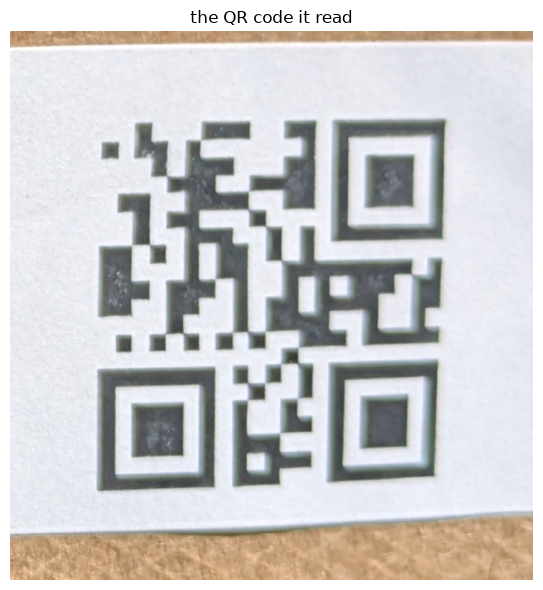

In [17]:
first_photo = ImageOps.exif_transpose(
    Image.open(os.path.join(IMAGE_FOLDER, image_files[10]))).convert("RGB")

started = time.time()
qr_text, qr_corners = read_qr_code(first_photo)
print(f"{image_files[0]}  ->  {qr_text}      ({time.time() - started:.2f} seconds)")

if qr_corners is None:
    print("\nNo QR code read in this photo. If you expected one, open the photo")
    print("and check that the label is in frame, in focus and facing the camera.")
else:
    xs = [x for x, _ in qr_corners]
    ys = [y for _, y in qr_corners]
    pad = 120
    box = (max(0, int(min(xs) - pad)), max(0, int(min(ys) - pad)),
           int(max(xs) + pad), int(max(ys) + pad))
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.imshow(first_photo.crop(box))
    ax.set_title("the QR code it read", fontsize=12)
    ax.axis("off")
    plt.tight_layout()
    plt.show()

---
## Step 4 — Drawing on the saved copies

Only used when `SAVE_ANNOTATED_IMAGES` is `True`. It draws a yellow box around
every stem the model counted and a cyan outline around the QR code, then saves
the result as a new JPEG in `ANNOTATED_IMAGE_FOLDER`.

**Your original photos are never modified.** Copies are written to a different
folder, with `_annotated` added to the name.

In [18]:
def _label_font(size):
    """A readable font at a sensible size, whatever version of Pillow is installed."""
    try:
        return ImageFont.load_default(size=size)      # Pillow 10.1 and newer
    except TypeError:
        return ImageFont.load_default()               # older Pillow: small, but works


def save_annotated_copy(photo, boxes, qr_corners, qr_text, out_path):
    """Save a copy of the photo with the counted stems and the QR code marked."""
    canvas = photo.copy()
    pen    = ImageDraw.Draw(canvas)

    # Scale the line thickness to the photo, so it is visible on a big image
    # and not overwhelming on a small one.
    thickness = max(2, round(min(canvas.size) / 700))

    for left, top, right, bottom in boxes:
        pen.rectangle([left, top, right, bottom],
                      outline=COLOR_PREDICTION, width=thickness)

    if qr_corners is not None:
        pen.line(list(qr_corners) + [qr_corners[0]],
                 fill=COLOR_QR, width=thickness * 2, joint="curve")

    # A caption in the top-left corner: the count, and the QR text.
    font    = _label_font(max(20, round(min(canvas.size) / 45)))
    caption = f"{len(boxes)} stems   |   {qr_text}"
    pen.text((thickness * 6, thickness * 6), caption,
             fill=COLOR_PREDICTION, font=font,
             stroke_width=max(1, thickness // 2), stroke_fill="black")

    canvas.save(out_path, quality=90)


print("Ready. This is only used if SAVE_ANNOTATED_IMAGES is True.")

Ready. This is only used if SAVE_ANNOTATED_IMAGES is True.


---
## Step 5 — Run it

This is the long cell. The progress bar shows how far it has got and estimates
how long is left.

If one photo causes trouble — a corrupt file, an unreadable format — the loop
does **not** stop. It records the problem in the `notes` column, leaves the
count blank, and carries on. At the end you get a list of anything that went
wrong, so a failure can never quietly look like a real count of zero.

You can safely leave this running and come back to it.

In [19]:
rows     = []
problems = []

started = time.time()

for filename in tqdm(image_files, desc="counting photos", unit="photo"):
    full_path = os.path.join(IMAGE_FOLDER, filename)

    try:
        # Open the photo and undo any sideways-photo rotation (see notebook 1).
        photo = ImageOps.exif_transpose(Image.open(full_path)).convert("RGB")

        # Count the stems.
        boxes, scores = count_stems(np.array(photo), model, DEVICE)

        # Read the label.
        qr_text, qr_corners = read_qr_code(photo)

        rows.append({"image_name": filename,
                     "predicted_count": len(boxes),
                     "qr_code": qr_text,
                     "notes": ""})

        if SAVE_ANNOTATED_IMAGES:
            out_name = os.path.splitext(filename)[0] + "_annotated.jpg"
            save_annotated_copy(photo, boxes, qr_corners, qr_text,
                                os.path.join(ANNOTATED_IMAGE_FOLDER, out_name))

    except Exception as error:
        # Record it and keep going.
        problems.append((filename, f"{type(error).__name__}: {error}"))
        rows.append({"image_name": filename,
                     "predicted_count": None,
                     "qr_code": NOT_FOUND,
                     "notes": f"FAILED - {type(error).__name__}: {error}"})

elapsed = time.time() - started
print(f"\nFinished {len(image_files)} photos in {elapsed/60:.1f} minutes "
      f"({elapsed/max(1,len(image_files)):.1f} seconds each, on {DEVICE}).")

if problems:
    print(f"\n{len(problems)} photo(s) could not be processed:")
    for filename, message in problems:
        print(f"   {filename}: {message}")
else:
    print("Every photo was processed successfully.")

counting photos:   0%|          | 0/48 [00:00<?, ?photo/s]


Finished 48 photos in 7.9 minutes (9.9 seconds each, on cpu).
Every photo was processed successfully.


---
## Step 6 — Save the spreadsheet

In [11]:
counts = pd.DataFrame(rows, columns=["image_name", "predicted_count", "qr_code", "notes"])
counts.to_csv(OUTPUT_CSV, index=False)

print(f"Saved {len(counts)} rows to {OUTPUT_CSV}\n")
counts.head(10)

Saved 48 rows to Outputs/stem_counts.csv



,image_name,predicted_count,qr_code,notes
0,0287_JPG_JPG.rf.KWOEVVgAQtx7YDN06M4V.JPG,99,N/A,
1,0616_JPG_JPG.rf.ZdUa8JPWp0AwnjMls1ds.JPG,178,N/A,
2,0847_JPG_JPG.rf.78uwNZ8zQuuiA39F3ZdR.JPG,46,N/A,
3,12A_Q1_JPG.rf.39fXM0vMUL99vYDTY2Vx.JPG,197,KiSSDVT_CO_Akron_12A_2023_GrainQuadrant_1_,
4,1506_JPG_JPG.rf.MBVLQz4LjLFAYaYeifyo.JPG,84,N/A,
5,1_jpg.rf.Hc57mLq4dN1T3hjGNjMd.jpg,24,N/A,
6,211_jpg.rf.y35NA0CZQBlReDO3ASlA.jpg,44,N/A,
7,212_jpg.rf.A3Fs4DXfWvCP4pSyoTiK.jpg,38,MUS.201.a.veg,
8,213_jpg.rf.GScECxqqH45iJkvZyCUX.jpg,107,MUS.301.a.veg,
9,214_jpg.rf.MjyzE84vgdst3UrxNk77.jpg,83,MUS.101.a.veg,


The file is an ordinary CSV, so it opens in Excel, Numbers, Google Sheets or
R. On Colab, open the folder icon in the left-hand sidebar, find the file, and
use its ⋮ menu to download it — Colab throws its files away when the session
ends, so **download it before you close the tab**.

---
## Step 7 — A quick look at the results

Not an accuracy check — there are no hand counts here to compare against. This
is a sanity check: are the numbers the right sort of size, and did the QR
reading work?

photos counted        : 48 of 48
total stems           : 6,754
average per photo     : 141
smallest / largest    : 3 / 387

QR code read          : 29 of 48 photos
no QR code read       : 19
   0287_JPG_JPG.rf.KWOEVVgAQtx7YDN06M4V.JPG
   0616_JPG_JPG.rf.ZdUa8JPWp0AwnjMls1ds.JPG
   0847_JPG_JPG.rf.78uwNZ8zQuuiA39F3ZdR.JPG
   1506_JPG_JPG.rf.MBVLQz4LjLFAYaYeifyo.JPG
   1_jpg.rf.Hc57mLq4dN1T3hjGNjMd.jpg
   211_jpg.rf.y35NA0CZQBlReDO3ASlA.jpg
   216_jpg.rf.VkJ09C3ZYZI3tI3XssS4.jpg
   218_jpg.rf.8fUIHtKznfo8ZVQBcWHT.jpg
   220_jpg.rf.4037SMUGA6mx47TkZg3d.jpg
   221_jpg.rf.oORPCBmCuk3xStmWDWUg.jpg
   ... and 9 more


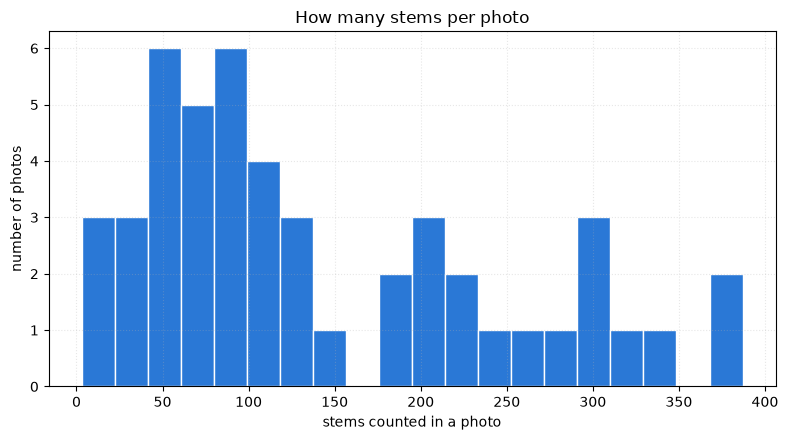

In [12]:
good = counts["predicted_count"].dropna()

print(f"photos counted        : {len(good)} of {len(counts)}")
if len(good):
    print(f"total stems           : {int(good.sum()):,}")
    print(f"average per photo     : {good.mean():.0f}")
    print(f"smallest / largest    : {int(good.min())} / {int(good.max())}")

read_ok = (counts["qr_code"] != NOT_FOUND).sum()
print(f"\nQR code read          : {read_ok} of {len(counts)} photos")
if read_ok < len(counts):
    print(f"no QR code read       : {len(counts) - read_ok}")
    missing = counts.loc[counts["qr_code"] == NOT_FOUND, "image_name"].tolist()
    for name in missing[:10]:
        print(f"   {name}")
    if len(missing) > 10:
        print(f"   ... and {len(missing) - 10} more")

if len(good) > 1:
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.hist(good, bins=min(20, max(5, len(good) // 2)),
            color="#2a78d6", edgecolor="white")
    ax.set_xlabel("stems counted in a photo")
    ax.set_ylabel("number of photos")
    ax.set_title("How many stems per photo", fontsize=12)
    ax.grid(alpha=0.3, linestyle=":")
    plt.tight_layout()
    plt.show()

A count far outside the rest of the range is worth opening the photo for. The
usual causes are a photo where the cut ends are not facing the camera, a sheaf
photographed from too far away, or two sheaves in one frame.

---
## Step 8 — Check a few by eye

The counts are only as trustworthy as the photos. Set
`SAVE_ANNOTATED_IMAGES = True` in the settings cell, re-run from step 5, and
look at a handful of the saved copies — especially the highest and lowest
counts.

The cell below shows one of them here in the notebook if they exist.

In [13]:
if not SAVE_ANNOTATED_IMAGES:
    print("SAVE_ANNOTATED_IMAGES is False, so no copies were saved.")
    print("To make some: set it to True in the settings cell, then re-run step 5.")
elif not os.path.isdir(ANNOTATED_IMAGE_FOLDER):
    print(f"The folder {ANNOTATED_IMAGE_FOLDER} does not exist yet.")
    print("Run the settings cell and step 5 again with SAVE_ANNOTATED_IMAGES = True.")
else:
    saved = sorted(f for f in os.listdir(ANNOTATED_IMAGE_FOLDER)
                   if f.lower().endswith(".jpg"))
    print(f"{len(saved)} annotated copies in {ANNOTATED_IMAGE_FOLDER}")

    if saved:
        # show the photo with the most stems - the hardest one to get right
        busiest = counts.dropna(subset=["predicted_count"]).nlargest(1, "predicted_count")
        name = os.path.splitext(busiest["image_name"].iloc[0])[0] + "_annotated.jpg"
        path = os.path.join(ANNOTATED_IMAGE_FOLDER, name)
        if not os.path.exists(path):
            path = os.path.join(ANNOTATED_IMAGE_FOLDER, saved[0])

        picture = Image.open(path)
        fig, axes = plt.subplots(1, 2, figsize=(15, 8))
        axes[0].imshow(picture)
        axes[0].set_title(os.path.basename(path), fontsize=11)
        axes[0].axis("off")

        # A zoom, because the boxes are tiny at full size. Centre it on the
        # boxes themselves rather than the middle of the photo: find the
        # pixels that are close to the box colour, and take their middle.
        w, h = picture.size
        side = min(w, h) // 4
        pixels = np.array(picture.convert("RGB")).astype(int)
        box_rgb = [int(COLOR_PREDICTION[i:i + 2], 16) for i in (1, 3, 5)]
        looks_yellow = np.abs(pixels - np.array(box_rgb)).sum(axis=2) < 90
        if looks_yellow.sum() > 100:
            ys, xs = np.nonzero(looks_yellow)
            centre_x, centre_y = int(np.median(xs)), int(np.median(ys))
        else:
            centre_x, centre_y = w // 2, h // 2
        left = max(0, min(centre_x - side // 2, w - side))
        top  = max(0, min(centre_y - side // 2, h - side))
        axes[1].imshow(picture.crop((left, top, left + side, top + side)))
        axes[1].set_title("zoomed in on the boxes", fontsize=11)
        axes[1].axis("off")
        plt.tight_layout()
        plt.show()

SAVE_ANNOTATED_IMAGES is False, so no copies were saved.
To make some: set it to True in the settings cell, then re-run step 5.


---
## If something went wrong

| what you saw | what it usually means |
|---|---|
| `FileNotFoundError` in step 1 | `IMAGE_FOLDER` or `WEIGHTS_PATH` does not match where the notebook is running. The error prints the folder it is looking in. |
| "No photos in ..." | The folder is empty, or your photos use an extension not in `IMAGE_EXTENSIONS`. |
| `NameError: 'model' is not defined` | A cell was skipped. Run the cells in order from the top. |
| Every `qr_code` says `N/A` | Possible, if the photos have no labels. If you expected codes, open one photo and check the label is in frame, in focus and not folded. |
| Step 5 is very slow | No graphics card. On Colab: *Runtime → Change runtime type → T4 GPU*, then re-run from step 0. |
| Colab disconnected part-way | Colab stops idle sessions. Keep the tab visible, or run in smaller batches by moving some photos into a separate folder. |
| The counts look far too low | Check one photo in `01_visualize_one_image.ipynb`. The usual cause is photos where the cut stem ends are not square-on to the camera. |

### A note on what the counts mean

The model was trained on photographs of Kernza sheaves with the **cut ends
facing the camera**, filling most of the frame, in natural light. It counts
what it can see. A photo taken from further away, at an angle, or with stems
partly hidden behind others will give a lower count — not because the model is
broken, but because fewer stem ends are visible.

Consistency is what makes counts comparable. Photograph every sample the same
way and the numbers can be compared with each other. That matters more than any
setting in this notebook.